In [1]:
from pathlib import Path
from statistics import NormalDist
import json, math, warnings, zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
OUT = ROOT / "outputs_fame_gpu_03b"
OUT.mkdir(exist_ok=True)

PRIMARY_GPU = "A100-SXM4-80GB"
TRACE_ORIGIN = pd.Timestamp("2024-03-01 00:00:00")
CAPACITY = 3456

HORIZON = 4
DEV_VALIDATION_DAYS = 7
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]



Q_GRID = [0.50, 0.80, 0.90, 0.95, 0.99]
H_GRID = [1, 2, 4]

print("PRIMARY_GPU:", PRIMARY_GPU)
print("CAPACITY:", CAPACITY)

PRIMARY_GPU: A100-SXM4-80GB
CAPACITY: 3456


In [2]:
def locate_file(candidates):
    for p in candidates:
        p = Path(p)
        if p.exists():
            return p
    return None


out1 = None
for p in [ROOT/"outputs_fame_gpu", Path("/mnt/data/outputs_fame_gpu")]:
    if (p/"fame_windows_7d.csv").exists():
        out1 = p
        break

if out1 is None:
    zpath = locate_file([
        ROOT/"outputs_fame_gpu.zip",
        Path("/mnt/data/outputs_fame_gpu.zip")
    ])
    if zpath is None:
        raise FileNotFoundError("outputs_fame_gpu ou outputs_fame_gpu.zip não encontrado.")
    target = ROOT/"outputs_fame_gpu_03b_extract"
    target.mkdir(exist_ok=True)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(target)
    out1 = target/"outputs_fame_gpu"

windows = pd.read_csv(
    out1/"fame_windows_7d.csv",
    parse_dates=["D_start","D_end_exclusive","C_start","C_end_exclusive","E_start","E_end_exclusive"]
)


data_dir = None
for p in [ROOT/"data_fame_gpu", Path("/mnt/data/data_fame_gpu")]:
    if (p/"job_info_df.csv").exists():
        data_dir = p
        break

if data_dir is None:
    raise FileNotFoundError(
        "Pasta data_fame_gpu não encontrada. "
        "Use a mesma pasta baixada pelo Notebook 01."
    )

jobs = pd.read_csv(data_dir/"job_info_df.csv")
nodes = pd.read_csv(data_dir/"node_info_df.csv")

a100 = jobs[jobs["gpu_model"] == PRIMARY_GPU].copy()
a100["submit_time"] = pd.to_numeric(a100["submit_time"], errors="coerce")
a100["duration"] = pd.to_numeric(a100["duration"], errors="coerce")
a100["gpu_request"] = pd.to_numeric(a100["gpu_request"], errors="coerce")
a100["worker_num"] = pd.to_numeric(a100["worker_num"], errors="coerce")

a100["physical_gpus"] = a100["gpu_request"] * a100["worker_num"]
a100["end_time"] = a100["submit_time"] + a100["duration"]

print("A100 jobs:", len(a100))
print("HP:", (a100["job_type"]=="HP").sum(), "Spot:", (a100["job_type"]=="Spot").sum())
display(windows)

A100 jobs: 169020
HP: 137396 Spot: 31624


,replication,D_start,D_end_exclusive,C_start,C_end_exclusive,E_start,E_end_exclusive
0,R01,2024-03-01,2024-04-26,2024-04-26,2024-05-03,2024-05-03,2024-05-10
1,R02,2024-03-01,2024-05-10,2024-05-10,2024-05-17,2024-05-17,2024-05-24
2,R03,2024-03-01,2024-05-24,2024-05-24,2024-05-31,2024-05-31,2024-06-07
3,R04,2024-03-01,2024-06-07,2024-06-07,2024-06-14,2024-06-14,2024-06-21
4,R05,2024-03-01,2024-06-21,2024-06-21,2024-06-28,2024-06-28,2024-07-05
5,R06,2024-03-01,2024-07-05,2024-07-05,2024-07-12,2024-07-12,2024-07-19
6,R07,2024-03-01,2024-07-19,2024-07-19,2024-07-26,2024-07-26,2024-08-02
7,R08,2024-03-01,2024-08-02,2024-08-02,2024-08-09,2024-08-09,2024-08-16
8,R09,2024-03-01,2024-08-16,2024-08-16,2024-08-23,2024-08-23,2024-08-30


In [3]:
trace_end_sec = int(np.ceil(a100["end_time"].max()))
n_minutes = int(np.ceil(trace_end_sec / 60)) + 2

minute_index = pd.date_range(
    TRACE_ORIGIN,
    periods=n_minutes,
    freq="min"
)

def offered_load_minute(df, weight_col):
    diff = np.zeros(n_minutes + 1, dtype=float)

    starts = np.floor(df["submit_time"].to_numpy() / 60).astype(int)
    ends = np.ceil(df["end_time"].to_numpy() / 60).astype(int)
    weights = df[weight_col].to_numpy(dtype=float)

    starts = np.clip(starts, 0, n_minutes)
    ends = np.clip(ends, 0, n_minutes)

    np.add.at(diff, starts, weights)
    np.add.at(diff, ends, -weights)

    return np.cumsum(diff[:-1])

hp_df = a100[a100["job_type"]=="HP"].copy()
spot_df = a100[a100["job_type"]=="Spot"].copy()

minute = pd.DataFrame(index=minute_index)
minute["HP_physical"] = offered_load_minute(hp_df, "physical_gpus")
minute["HP_gfs_proxy"] = offered_load_minute(hp_df, "gpu_request")
minute["Spot_physical"] = offered_load_minute(spot_df, "physical_gpus")

display(minute.describe(percentiles=[.5,.9,.95,.99]).T)

,count,mean,std,min,50%,90%,95%,99%,max
HP_physical,265066.0,2478.892459,462.809717,0.0,2441.5,3097.0,3208.0,3391.0,3988.0
HP_gfs_proxy,265066.0,1925.769342,283.227590,0.0,1913.5,2320.5,2405.0,2519.0,2630.0
Spot_physical,265066.0,88.268956,89.492232,0.0,63.0,211.0,273.0,357.0,763.0


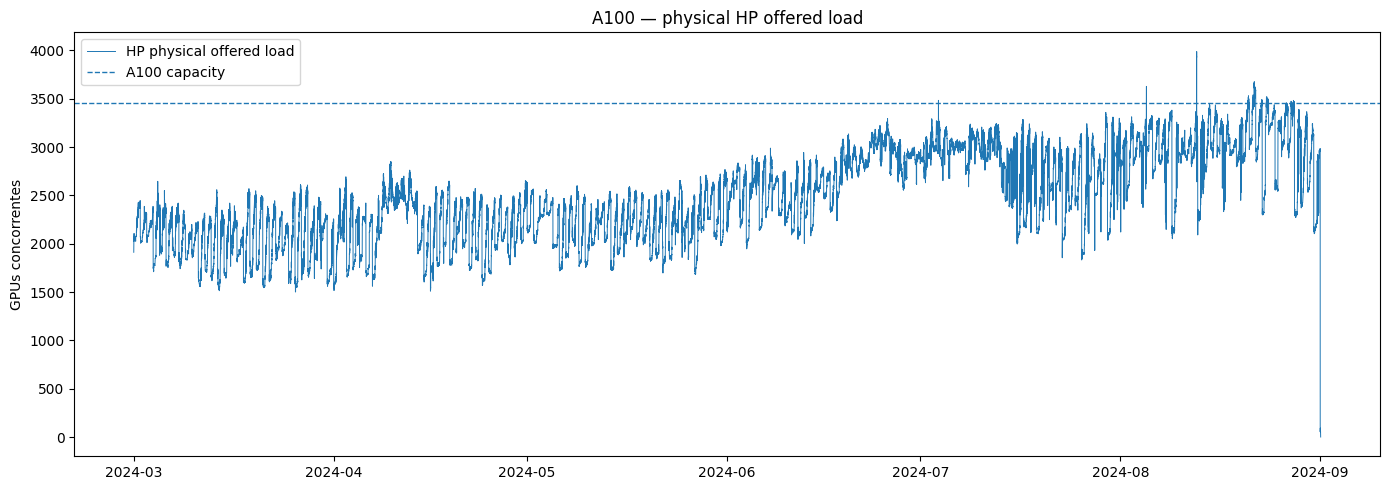

In [4]:
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(minute.index, minute["HP_physical"], linewidth=.7, label="HP physical offered load")
ax.axhline(CAPACITY, linestyle="--", linewidth=1, label="A100 capacity")
ax.set_title("A100 — physical HP offered load")
ax.set_ylabel("GPUs concorrentes")
ax.legend()
plt.tight_layout()
plt.show()

In [5]:
hourly = pd.DataFrame({
    "HP_physical_max": minute["HP_physical"].resample("h").max(),
    "HP_gfs_proxy_max": minute["HP_gfs_proxy"].resample("h").max(),
    "Spot_physical_max": minute["Spot_physical"].resample("h").max(),
    "HP_physical_mean": minute["HP_physical"].resample("h").mean(),
    "Spot_physical_mean": minute["Spot_physical"].resample("h").mean(),
})


trace_last = TRACE_ORIGIN + pd.to_timedelta(jobs["submit_time"].max(), unit="s")
hourly = hourly.loc[:trace_last.floor("h")].copy()

display(hourly.describe(percentiles=[.5,.9,.95,.99]).T)
hourly.to_csv(OUT/"a100_offered_load_hourly.csv")

,count,mean,std,min,50%,90%,95%,99%,max
HP_physical_max,4418.0,2519.190471,469.825084,70.000000,2483.000000,3140.000000,3250.000000,3441.830000,3988.000000
HP_gfs_proxy_max,4418.0,1946.578995,285.178494,68.000000,1937.000000,2342.300000,2429.075000,2548.830000,2630.000000
Spot_physical_max,4418.0,101.883884,98.871729,0.000000,76.000000,235.000000,295.150000,385.830000,763.000000
HP_physical_mean,4418.0,2478.763377,460.529715,34.826087,2442.741667,3085.440000,3194.275000,3390.866833,3643.433333
Spot_physical_mean,4418.0,88.264611,87.748847,0.000000,64.733333,209.816667,270.336667,347.391917,649.166667


In [6]:
def active_load_at(ts):
    sec = (pd.Timestamp(ts) - TRACE_ORIGIN).total_seconds()
    z = hp_df[(hp_df["submit_time"] <= sec) & (hp_df["end_time"] > sec)].copy()

    total = z["physical_gpus"].sum()
    old = z[z["submit_time"] < sec - 2*86400]["physical_gpus"].sum()

    return {
        "total_active_HP_gpus": float(total),
        "older_than_48h_gpus": float(old),
        "older_than_48h_share": float(old/total) if total>0 else 0.0,
        "active_jobs": int(len(z)),
        "old_active_jobs": int((z["submit_time"] < sec - 2*86400).sum()),
    }

carry_rows=[]
for w in windows.itertuples(index=False):
    for period, ts in [("C",w.C_start),("E",w.E_start)]:
        d = active_load_at(ts)
        carry_rows.append({"replication":w.replication,"period":period,"timestamp":ts,**d})

carry = pd.DataFrame(carry_rows)
display(carry)
print("\nResumo share de carga ativa com idade >48h:")
display(carry["older_than_48h_share"].describe().to_frame("value"))
carry.to_csv(OUT/"carry_in_48h_audit.csv", index=False)

,replication,period,timestamp,total_active_HP_gpus,older_than_48h_gpus,older_than_48h_share,active_jobs,old_active_jobs
0,R01,C,2024-04-26,1956.5,1223.5,0.625351,715,560
1,R01,E,2024-05-03,2280.5,1784.5,0.782504,766,677
2,R02,C,2024-05-10,1816.5,1336.5,0.735756,745,592
3,R02,E,2024-05-17,2166.5,1349.5,0.622894,785,559
4,R03,C,2024-05-24,1987.0,1369.0,0.688978,695,602
5,R03,E,2024-05-31,1980.0,1477.0,0.745960,715,607
6,R04,C,2024-06-07,2327.0,1686.0,0.724538,791,655
7,R04,E,2024-06-14,2081.0,1571.0,0.754926,781,641
8,R05,C,2024-06-21,2884.0,1596.0,0.553398,934,699
9,R05,E,2024-06-28,2792.0,1671.0,0.598496,902,664



Resumo share de carga ativa com idade >48h:


,value
count,18.000000
mean,0.677301
std,0.078893
min,0.525997
25%,0.612885
50%,0.706558
75%,0.735440
max,0.782504


In [7]:
y = hourly["HP_physical_max"].copy()

LAGS = [1,2,3,4,6,12,24,48,72,168]
ROLLS = [6,24,168]

def build_features(y):
    X = pd.DataFrame(index=y.index)
    X["y_now"] = y

    for lag in LAGS:
        X[f"lag_{lag}"] = y.shift(lag)

    past = y.shift(1)
    for w in ROLLS:
        X[f"roll_mean_{w}"] = past.rolling(w, min_periods=max(3,w//4)).mean()
        X[f"roll_std_{w}"] = past.rolling(w, min_periods=max(3,w//4)).std()
        X[f"roll_max_{w}"] = past.rolling(w, min_periods=max(3,w//4)).max()

    hour = X.index.hour
    dow = X.index.dayofweek
    X["sin_hour"] = np.sin(2*np.pi*hour/24)
    X["cos_hour"] = np.cos(2*np.pi*hour/24)
    X["sin_dow"] = np.sin(2*np.pi*dow/7)
    X["cos_dow"] = np.cos(2*np.pi*dow/7)

    for h in range(1,HORIZON+1):
        X[f"target_h{h}"] = y.shift(-h)

    return X

X = build_features(y)
FEATURES = [c for c in X.columns if not c.startswith("target_")]

def fit_replication(w):
    D0,D1 = w.D_start,w.D_end_exclusive
    v1 = D1
    v0 = v1 - pd.Timedelta(days=DEV_VALIDATION_DAYS)

    train_idx = X.index[(X.index>=D0)&(X.index<v0)]
    val_idx = X.index[(X.index>=v0)&(X.index<v1)]

    scores=[]
    for alpha in RIDGE_ALPHAS:
        maes=[]
        for h in range(1,HORIZON+1):
            t=f"target_h{h}"
            tr=X.loc[train_idx, FEATURES+[t]].dropna()
            va=X.loc[val_idx, FEATURES+[t]].dropna()
            m=Pipeline([("scale",StandardScaler()),("ridge",Ridge(alpha=alpha))])
            m.fit(tr[FEATURES],tr[t])
            p=np.maximum(m.predict(va[FEATURES]),0)
            maes.append(mean_absolute_error(va[t],p))
        scores.append((alpha,np.mean(maes)))

    best_alpha=min(scores,key=lambda x:x[1])[0]

    models={}
    sigmas={}
    full_idx=X.index[(X.index>=D0)&(X.index<D1)]

    for h in range(1,HORIZON+1):
        t=f"target_h{h}"

        
        tr=X.loc[train_idx, FEATURES+[t]].dropna()
        va=X.loc[val_idx, FEATURES+[t]].dropna()
        mv=Pipeline([("scale",StandardScaler()),("ridge",Ridge(alpha=best_alpha))])
        mv.fit(tr[FEATURES],tr[t])
        pv=np.maximum(mv.predict(va[FEATURES]),0)
        resid=va[t].to_numpy()-pv
        mad=np.median(np.abs(resid-np.median(resid)))
        sigma=1.4826*mad
        if not np.isfinite(sigma) or sigma<=0:
            sigma=np.std(resid,ddof=1)
        sigmas[h]=max(float(sigma),1e-8)

        full=X.loc[full_idx, FEATURES+[t]].dropna()
        mf=Pipeline([("scale",StandardScaler()),("ridge",Ridge(alpha=best_alpha))])
        mf.fit(full[FEATURES],full[t])
        models[h]=mf

    return best_alpha,models,sigmas

In [8]:
pred_rows=[]

for w in windows.itertuples(index=False):
    alpha,models,sigmas=fit_replication(w)

    for period,start,end in [
        ("C",w.C_start,w.C_end_exclusive),
        ("E",w.E_start,w.E_end_exclusive)
    ]:
        origins=X.index[(X.index>=start)&(X.index<end)]
        for origin in origins:
            row=X.loc[[origin],FEATURES]
            if row.isna().any(axis=None):
                continue

            for h in range(1,HORIZON+1):
                tt=origin+pd.Timedelta(hours=h)
                if tt not in y.index:
                    continue
                pred_rows.append({
                    "replication":w.replication,
                    "period":period,
                    "origin":origin,
                    "horizon":h,
                    "y_true":float(y.loc[tt]),
                    "mu":max(float(models[h].predict(row)[0]),0),
                    "sigma":sigmas[h],
                    "alpha":alpha,
                })

pred = pd.DataFrame(pred_rows)
pred.to_csv(OUT/"physical_hp_ridge_predictions.csv.gz",index=False,compression="gzip")
print(pred.shape)
display(pred.head())

(12096, 8)


,replication,period,origin,horizon,y_true,mu,sigma,alpha
0,R01,C,2024-04-26 00:00:00,1,1993.5,1964.930989,73.593602,10.0
1,R01,C,2024-04-26 00:00:00,2,1968.5,1925.620099,120.714150,10.0
2,R01,C,2024-04-26 00:00:00,3,1983.5,1911.238722,135.289212,10.0
3,R01,C,2024-04-26 00:00:00,4,1982.5,1890.899925,133.838486,10.0
4,R01,C,2024-04-26 01:00:00,1,1968.5,1932.096546,73.593602,10.0


In [9]:
metric_rows=[]
for (rep,period),g in pred.groupby(["replication","period"]):
    maes=[]; rmses=[]; biases=[]
    for h,gh in g.groupby("horizon"):
        yt=gh["y_true"].to_numpy()
        yp=gh["mu"].to_numpy()
        maes.append(mean_absolute_error(yt,yp))
        rmses.append(np.sqrt(mean_squared_error(yt,yp)))
        biases.append(np.mean(yp-yt))
    metric_rows.append({
        "replication":rep,
        "period":period,
        "MAE":np.mean(maes),
        "RMSE":np.mean(rmses),
        "bias":np.mean(biases),
    })

pm = pd.DataFrame(metric_rows)
wide = pm.pivot(index="replication",columns="period",values=["MAE","RMSE","bias"])
wide.columns=[f"{a}_{b}" for a,b in wide.columns]
wide=wide.reset_index()
wide["delta_RMSE_pct"]=100*(wide["RMSE_E"]-wide["RMSE_C"])/wide["RMSE_C"]
wide["delta_MAE_pct"]=100*(wide["MAE_E"]-wide["MAE_C"])/wide["MAE_C"]

display(wide)
wide.to_csv(OUT/"physical_predictive_transfer.csv",index=False)

,replication,MAE_C,MAE_E,RMSE_C,RMSE_E,bias_C,bias_E,delta_RMSE_pct,delta_MAE_pct
0,R01,82.593321,100.492893,105.466488,127.059763,-39.783573,-48.711763,20.474063,21.671937
1,R02,77.394220,90.549163,104.110678,114.102679,-19.372156,-26.048145,9.597479,16.997319
2,R03,96.076126,134.740275,133.939840,175.178750,-27.891339,-82.335452,30.789129,40.243243
3,R04,85.768939,85.095188,121.884316,106.096453,2.894993,-54.850404,-12.953154,-0.785542
4,R05,105.291750,107.281925,128.474058,127.911982,-30.721739,-18.952603,-0.437502,1.890153
5,R06,72.524090,191.993560,91.767990,257.668522,-0.302668,23.414495,180.782571,164.730739
6,R07,127.346607,127.142629,195.220846,181.778960,17.209384,-0.703092,-6.885477,-0.160175
7,R08,101.902916,124.372474,177.786571,200.864621,2.774504,29.383769,12.980761,22.049966
8,R09,102.492981,132.267020,166.047294,201.283756,7.701242,1.156325,21.220738,29.049832


In [10]:
grid = pd.MultiIndex.from_product([Q_GRID,H_GRID],names=["q","H"]).to_frame(index=False)

binding_rows=[]
quota_rows=[]

for (rep,period),g in pred.groupby(["replication","period"]):
    piv_mu=g.pivot(index="origin",columns="horizon",values="mu")
    piv_sg=g.pivot(index="origin",columns="horizon",values="sigma")

    for q,H in grid.itertuples(index=False):
        zq=NormalDist().inv_cdf(q)
        reserves=[]

        for h in range(1,int(H)+1):
            reserve=(piv_mu[h]+zq*piv_sg[h]).clip(0,CAPACITY)
            reserves.append(reserve)

        reserve_max=pd.concat(reserves,axis=1).max(axis=1)
        quota=(CAPACITY-reserve_max).clip(0,CAPACITY)

        spot_now=hourly["Spot_physical_max"].reindex(quota.index).fillna(0)
        binds=spot_now>quota

        binding_rows.append({
            "replication":rep,
            "period":period,
            "q":q,
            "H":H,
            "quota_min":float(quota.min()),
            "quota_median":float(quota.median()),
            "quota_mean":float(quota.mean()),
            "quota_max":float(quota.max()),
            "spot_offered_mean":float(spot_now.mean()),
            "spot_offered_max":float(spot_now.max()),
            "binding_share_offered":float(binds.mean()),
            "mean_excess_when_binding":float((spot_now[binds]-quota[binds]).mean()) if binds.any() else 0.0,
        })

        for ts,val in quota.items():
            quota_rows.append({
                "replication":rep,"period":period,"origin":ts,
                "q":q,"H":H,"quota":float(val),
                "spot_offered":float(spot_now.loc[ts]),
            })

binding=pd.DataFrame(binding_rows)
quota_long=pd.DataFrame(quota_rows)

display(
    binding.sort_values(
        ["binding_share_offered","mean_excess_when_binding"],
        ascending=False
    ).head(30)
)

binding.to_csv(OUT/"binding_audit.csv",index=False)
quota_long.to_csv(OUT/"candidate_quota_long.csv.gz",index=False,compression="gzip")

,replication,period,q,H,quota_min,quota_median,quota_mean,quota_max,spot_offered_mean,spot_offered_max,binding_share_offered,mean_excess_when_binding
239,R08,E,0.99,4,0.00000,0.000000,97.824551,665.073184,244.380952,763.0,0.821429,222.783661
164,R06,C,0.99,4,0.00000,113.306012,124.381185,382.125298,227.285714,379.0,0.767857,164.759612
224,R08,C,0.99,4,0.00000,0.000000,69.738455,422.789533,157.101190,427.0,0.761905,164.183647
254,R09,C,0.99,4,0.00000,0.000000,84.931647,559.339847,145.535714,311.0,0.738095,123.871119
163,R06,C,0.99,2,0.00000,185.764947,182.732734,435.830547,227.285714,379.0,0.678571,124.917813
236,R08,E,0.95,4,0.00000,82.926701,163.428787,793.496635,244.380952,763.0,0.666667,222.432392
238,R08,E,0.99,2,0.00000,109.089614,186.706627,883.651995,244.380952,763.0,0.642857,231.852778
221,R08,C,0.95,4,0.00000,88.626788,134.833172,551.212984,157.101190,427.0,0.636905,152.630544
269,R09,E,0.99,4,0.00000,0.000000,144.078399,733.360814,107.994048,207.0,0.636905,103.004773
223,R08,C,0.99,2,0.00000,78.796372,133.955938,594.571226,157.101190,427.0,0.630952,154.694171


In [11]:
binding_summary = (
    binding.groupby(["q","H"])
    .agg(
        mean_binding_share=("binding_share_offered","mean"),
        max_binding_share=("binding_share_offered","max"),
        n_windows_with_binding=("binding_share_offered",lambda x:(x>0).sum()),
        median_quota=("quota_median","median"),
    )
    .reset_index()
)

display(binding_summary)
binding_summary.to_csv(OUT/"binding_summary_by_candidate.csv",index=False)

,q,H,mean_binding_share,max_binding_share,n_windows_with_binding,median_quota
0,0.50,1,0.063161,0.285714,8,657.128786
1,0.50,2,0.076058,0.327381,8,630.863301
2,0.50,4,0.089947,0.375000,8,607.627958
3,0.80,1,0.104497,0.375000,9,584.700778
4,0.80,2,0.123347,0.458333,10,538.026631
5,0.80,4,0.156746,0.529762,10,450.250743
6,0.90,1,0.117063,0.416667,10,546.841375
7,0.90,2,0.156085,0.488095,10,481.847221
8,0.90,4,0.202712,0.601190,11,383.797408
9,0.95,1,0.136905,0.464286,10,515.576426


In [12]:
carry_problem = bool((carry["older_than_48h_share"] > 0.05).any())
any_binding = bool((binding["binding_share_offered"] > 0).any())

candidate_spread = (
    binding.groupby(["replication","period"])["quota_median"].max()
    - binding.groupby(["replication","period"])["quota_median"].min()
)

meaningful_spread = bool((candidate_spread > 50).any())

decision = {
    "carry_in_48h_problem": carry_problem,
    "any_candidate_binding": any_binding,
    "meaningful_candidate_quota_spread_gt_50_gpu": meaningful_spread,
    "GO_TO_DOC_SIMULATION": bool(any_binding and meaningful_spread),
}

display(pd.Series(decision).to_frame("value"))

with open(OUT/"go_no_go_03b.json","w",encoding="utf-8") as f:
    json.dump(decision,f,indent=2)

,value
carry_in_48h_problem,True
any_candidate_binding,True
meaningful_candidate_quota_spread_gt_50_gpu,True
GO_TO_DOC_SIMULATION,True


In [13]:
import zipfile

zip_out = ROOT/"outputs_fame_gpu_03b.zip"

with zipfile.ZipFile(zip_out,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(p,arcname=f"outputs_fame_gpu_03b/{p.name}")

print("ZIP criado:",zip_out.resolve())
print("Envie este arquivo na próxima mensagem.")

ZIP criado: C:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu_03b.zip
Envie este arquivo na próxima mensagem.
